# 10. Importancia de las variables clínicas

**Objetivo:** analizar la importancia relativa de las variables clínicas utilizadas en el experimento mediante un modelo de árbol de decisión.

Este análisis es complementario al modelo 1D-CNN. Su finalidad es facilitar la interpretación de las variables utilizadas en la clasificación y no modificar la arquitectura de la red neuronal.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

SEED = 42

DATA_PATH = Path("../../resultados/nuevo_experimento/cardio_15000.csv")
OUT_DIR = Path("../../resultados/nuevo_experimento")
FIG_DIR = OUT_DIR / "figuras"
TAB_DIR = OUT_DIR / "tablas"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, sep=";")

print("Dimensiones:", df.shape)
print("Nulos:", int(df.isnull().sum().sum()))
print("Duplicados:", int(df.duplicated().sum()))

Dimensiones: (15000, 13)
Nulos: 0
Duplicados: 0


## 1. Variables utilizadas

Se excluye `id` debido a que corresponde únicamente al identificador del registro. La variable `cardio` se utiliza como variable objetivo.

La edad, originalmente expresada en días, se transforma a años para facilitar su interpretación.

In [2]:
data = df.copy()

data["age"] = data["age"] / 365.25

X = data.drop(columns=["id", "cardio"])
y = data["cardio"]

print("Variables predictoras:")
print(X.columns.tolist())

print()
print("Variable objetivo: cardio")

Variables predictoras:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

Variable objetivo: cardio


## 2. División de los datos

Se utiliza una división estratificada para conservar aproximadamente la misma proporción de las clases de `cardio`.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (12000, 11)
X_test: (3000, 11)
y_train: (12000,)
y_test: (3000,)


## 3. Modelo utilizado para obtener la importancia

Se emplea un árbol de decisión como herramienta complementaria de interpretación. El modelo permite calcular una importancia relativa para cada variable predictora.

Esta importancia **no representa directamente los pesos internos de la CNN**. Se utiliza como análisis independiente para identificar qué variables presentan mayor capacidad de separación dentro del árbol.

In [4]:
tree = DecisionTreeClassifier(
    random_state=SEED,
    max_depth=5
)

tree.fit(X_train, y_train)

importance = pd.DataFrame({
    "variable": X.columns,
    "importancia": tree.feature_importances_
})

importance = importance.sort_values(
    "importancia",
    ascending=False
).reset_index(drop=True)

print(importance.to_string(index=False))

   variable  importancia
      ap_hi     0.747432
        age     0.151009
cholesterol     0.074941
     weight     0.010035
      ap_lo     0.008521
     height     0.003609
       gluc     0.002322
     active     0.001791
     gender     0.000341
      smoke     0.000000
       alco     0.000000


## 4. Traducción de las variables clínicas

Para facilitar la interpretación de los resultados se utilizan nombres descriptivos en español únicamente para las tablas y gráficos. Los nombres originales de las columnas se mantienen en el dataset y en el código.

In [5]:
nombres_es = {
    "age": "Edad",
    "gender": "Sexo",
    "height": "Altura",
    "weight": "Peso",
    "ap_hi": "Presión sistólica",
    "ap_lo": "Presión diastólica",
    "cholesterol": "Colesterol",
    "gluc": "Glucosa",
    "smoke": "Tabaquismo",
    "alco": "Consumo de alcohol",
    "active": "Actividad física"
}

importance["variable_es"] = importance["variable"].map(nombres_es)

importance_es = importance[
    ["variable", "variable_es", "importancia"]
].copy()

print(importance_es.to_string(index=False))

importance_es.to_csv(
    TAB_DIR / "importancia_variables.csv",
    index=False
)

   variable        variable_es  importancia
      ap_hi  Presión sistólica     0.747432
        age               Edad     0.151009
cholesterol         Colesterol     0.074941
     weight               Peso     0.010035
      ap_lo Presión diastólica     0.008521
     height             Altura     0.003609
       gluc            Glucosa     0.002322
     active   Actividad física     0.001791
     gender               Sexo     0.000341
      smoke         Tabaquismo     0.000000
       alco Consumo de alcohol     0.000000


## 5. Importancia relativa de las variables

La siguiente figura presenta las variables ordenadas desde la mayor hasta la menor importancia estimada por el árbol de decisión.

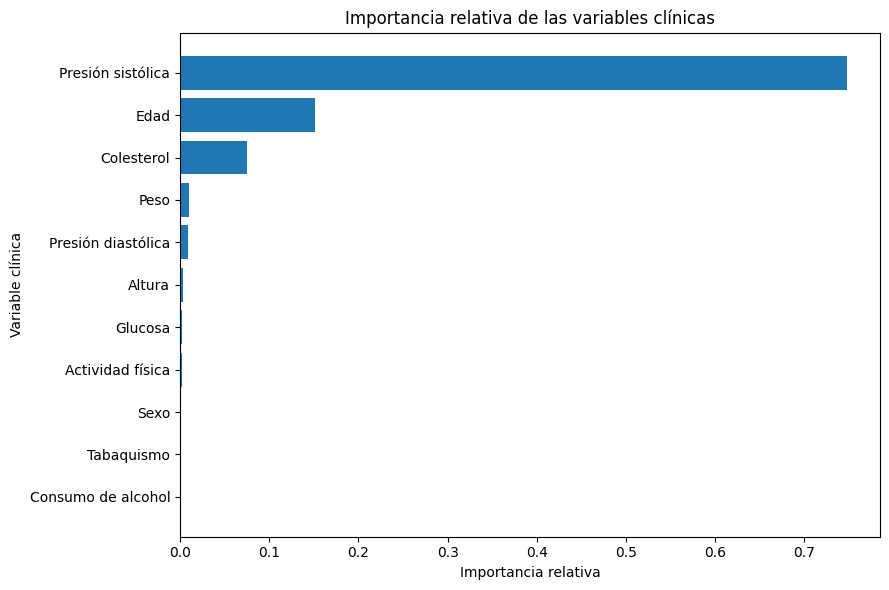

In [6]:
plot_df = importance_es.sort_values(
    "importancia",
    ascending=True
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    plot_df["variable_es"],
    plot_df["importancia"]
)

ax.set_xlabel("Importancia relativa")
ax.set_ylabel("Variable clínica")
ax.set_title("Importancia relativa de las variables clínicas")

fig.tight_layout()

fig.savefig(
    FIG_DIR / "importancia_variables.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Variables más importantes

Se identifican las variables con mayor importancia relativa según el árbol de decisión. Estos resultados se utilizan como evidencia complementaria para interpretar el conjunto de variables empleado por la CNN.

In [7]:
top_n = importance_es.head(5)

print("TOP 5 VARIABLES:")
print(
    top_n[
        ["variable_es", "importancia"]
    ].to_string(index=False)
)

print()
print(
    "La variable con mayor importancia estimada es:",
    top_n.iloc[0]["variable_es"]
)

TOP 5 VARIABLES:
       variable_es  importancia
 Presión sistólica     0.747432
              Edad     0.151009
        Colesterol     0.074941
              Peso     0.010035
Presión diastólica     0.008521

La variable con mayor importancia estimada es: Presión sistólica


## 7. Verificaciones

Se comprueba que todas las variables predictoras tengan una importancia calculada y que la suma de las importancias sea aproximadamente igual a uno.

In [8]:
print("Número de variables:", len(importance_es))
print("Suma de importancias:", importance_es["importancia"].sum())

assert len(importance_es) == 11
assert abs(importance_es["importancia"].sum() - 1.0) < 1e-9
assert importance_es["variable_es"].notnull().all()

print("Todas las verificaciones fueron satisfactorias.")

Número de variables: 11
Suma de importancias: 0.9999999999999999
Todas las verificaciones fueron satisfactorias.


## 8. Conclusión

El análisis mediante árbol de decisión permite ordenar las variables clínicas según su importancia relativa para la clasificación en este modelo complementario. La traducción de los nombres facilita la interpretación de los resultados, mientras que la conservación de los nombres originales garantiza la trazabilidad con el dataset.

Este análisis no sustituye la evaluación de la 1D-CNN ni representa directamente los pesos aprendidos por la red neuronal. Su función es proporcionar una interpretación complementaria de las variables clínicas utilizadas en el experimento.